# Weather time-series features with Zarr

> **Docs:** [Weather Features with Zarr — notebook walkthrough](https://databrickslabs.github.io/geobrix/docs/notebooks/zarr-weather-features) ·
> [Zarr Stores](https://databrickslabs.github.io/geobrix/docs/formats/zarr) ·
> [Zarr Reader](https://databrickslabs.github.io/geobrix/docs/readers/zarr) ·
> [Zarr Writer](https://databrickslabs.github.io/geobrix/docs/writers/zarr)

Weather and climate cubes are usually Zarr stores: N-dimensional arrays (`time` by `latitude` by
`longitude`) kept as many small chunk objects. This notebook takes one through a feature
workflow end to end, with GeoBrix's transactional Zarr stores:

1. **Register** the cube in place, as a Unity Catalog table. Nothing is copied.
2. **Read** a box of it, as N-dimensional blocks and as a table of cells.
3. **Sample** the hourly time series at 100 sites into a features table.
4. **Derive** wind speed from the wind components and **write it back** to the store as a new
   variable, in one transaction.
5. **Look at the history** and read the store as it was before the write.
6. **Map** the new variable as GeoBrix raster tiles, clipped to a polygon with `rst_clip`.
7. **Tag** the version that holds every variable of the features, so that it stays readable
   for training.

On the sample cube, the registration lists 19 objects and copies none of them, the new
`wind_speed` variable lands as one commit, and the tagged version reproduces all 4,800 rows of
the features table.

The outputs below are from a run on Serverless environment 6.

![Zarr weather features: register a cube in place, read and sample it, write a derived variable back, map it as tiles, tag the version](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/zarr-weather-features/zarr-weather-features.png)

## Install GeoBrix

Zarr runs in the lightweight tier, so there is no JAR. The notebook installs the env6 wheel with the
`zarr` and `vizx` extras. It targets **Serverless environment 6**. On a classic **Databricks Runtime 19**
cluster, install the same wheel and extras.

In [0]:
%pip install --quiet --disable-pip-version-check --no-deps --force-reinstall "geobrix @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"
%pip install --quiet "geobrix[zarr,vizx] @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"

In [0]:
%restart_python

## Settings

`CUBE` is the sample cube: two days of made-up hourly weather on a one-degree global grid,
`time` (48) by `latitude` (181) by `longitude` (360), with 2 m temperature `t2m`, the 10 m wind
components `u10` and `v10`, and mean sea level pressure `msl`. To make it in your own Volume, run
`write_era5_cube` from `databricks.labs.gbx.sample.zarr_era5` (see
[Zarr Stores](https://databrickslabs.github.io/geobrix/docs/formats/zarr#what-you-need)).

The notebook writes two tables to `CATALOG.SCHEMA`, and the files of its writes to a folder
under `WORK_DIR`. Point them at a schema and a Volume you can write to. Every run gets its own
`RUN_ID`, so its tables and folder never collide with another run's.

In [0]:
import uuid

CUBE = "/Volumes/geospatial_docs/geobrix/sample-data/geobrix-examples/global/era5-weather/era5_like_v3.zarr"

CATALOG = "geospatial_docs"
SCHEMA = "geobrix"
WORK_DIR = "/Volumes/geospatial_docs/geobrix/sample-data/_examples/zarr-weather"

RUN_ID = uuid.uuid4().hex[:8]
ROOT = f"{WORK_DIR}/{RUN_ID}"  # this run's files
STORE = f"{CATALOG}.{SCHEMA}.era5_weather_{RUN_ID}"  # the store's manifest table
FEATURES = f"{CATALOG}.{SCHEMA}.era5_site_features_{RUN_ID}"  # the features table
print("store table   :", STORE)
print("features table:", FEATURES)
print("files         :", ROOT)

store table   : geospatial_docs.geobrix.era5_weather_3b6f091e
features table: geospatial_docs.geobrix.era5_site_features_3b6f091e
files         : /Volumes/geospatial_docs/geobrix/sample-data/_examples/zarr-weather/3b6f091e


In [0]:
import json
import pathlib

import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from databricks.labs.gbx.pyrx import functions as rx
from databricks.labs.gbx.vizx import plot_raster
from databricks.labs.gbx.zarr import (
    block_to_numpy,
    gbx_zarr_history,
    gbx_zarr_read,
    gbx_zarr_register,
    gbx_zarr_sample,
    gbx_zarr_tag,
    gbx_zarr_write,
)


def fingerprint(store):
    """Every file of a store, with its size and modification time."""
    root = pathlib.Path(store)
    return sorted(
        (str(p.relative_to(root)), p.stat().st_size, p.stat().st_mtime)
        for p in root.rglob("*")
        if p.is_file()
    )


cube_before = fingerprint(CUBE)
print(len(cube_before), "files in the cube,", sum(size for _, size, _ in cube_before), "bytes")

19 files in the cube, 3643352 bytes


## 1. Register the cube in place

`gbx_zarr_register` lists the store once and writes one manifest row per array document and per
chunk (or shard) object, each pointing at the store's own file. Nothing is copied, and nothing in
the store is written. The manifest is a Delta table, so a version of the store **is** a version of
that table.

The registration is **writable**: writes go to an overlay folder that this table owns
(`overlay_root`), as new files, and the cube itself is never touched. GeoBrix prints a line for
each step; the sample cube has 7 arrays in 19 objects, and its registration is version 1.

In [0]:
version_registered = gbx_zarr_register(
    spark, CUBE, STORE, writable=True, overlay_root=f"{ROOT}/overlay"
)
print("registered at version", version_registered)

[register] listing the objects of /Volumes/geospatial_docs/geobrix/sample-data/geobrix-examples/global/era5-weather/era5_like_v3.zarr
[register] reading the metadata of /Volumes/geospatial_docs/geobrix/sample-data/geobrix-examples/global/era5-weather/era5_like_v3.zarr
[register] 7 array(s) found
[register] listed 19 object(s) in 11.1s
[register] committing 19 row(s) to geospatial_docs.geobrix.era5_weather_3b6f091e
[register] registered geospatial_docs.geobrix.era5_weather_3b6f091e at version 1: 11 object(s), 7 array(s), 1 group(s) in 33.2s
registered at version 1


The manifest is a table like any other. It has an `array` row for each of the 7 arrays (the four
variables and the `time`, `latitude` and `longitude` coordinates), a `group` row for the store's
root, a `chunk` row for each coordinate (each is one unsharded chunk), a `shard` row for each of
the two shards of each variable, and a `commit` row for the registration. The array documents
give the shapes and units:

In [0]:
spark.sql(f"""
    SELECT kind, count(*) AS rows FROM {STORE}
    WHERE tag IS NULL GROUP BY kind ORDER BY kind""").show()

arrays = {}
for row in spark.sql(
    f"SELECT array, meta FROM {STORE} WHERE kind = 'array' AND tag IS NULL ORDER BY array"
).collect():
    document = json.loads(row["meta"])
    arrays[row["array"]] = document
    attributes = document.get("attributes", {})
    print(f"{row['array']:<10} {str(document['shape']):<16} {attributes.get('units', '')}")

# The wind speed below is made from the 10 m wind components.
assert {"u10", "v10"} <= set(arrays), sorted(arrays)

+------+----+
|  kind|rows|
+------+----+
| array|   7|
| chunk|   3|
|commit|   1|
| group|   1|
| shard|   8|
+------+----+

latitude   [181]            degrees_north
longitude  [360]            degrees_east
msl        [48, 181, 360]   Pa
t2m        [48, 181, 360]   K
time       [48]             hours since 1900-01-01
u10        [48, 181, 360]   m s-1
v10        [48, 181, 360]   m s-1


## 2. Read a box: blocks, then a table

`gbx_zarr_read` selects by **label** with `sel` (or by position with `isel`). A label slice
includes both ends and follows the axis, so latitude runs from 60 down to 35. This box covers
Europe east of the Greenwich meridian, over the first day.

The default output is **blocks**: one row per variable and chunk the selection touches, holding
that chunk's selected cells as bytes. It is the N-dimensional form, the one `gbx_zarr_write` takes
back, and `block_to_numpy` turns a row into a NumPy array.

A chunk of the cube holds 12 hours by 91 latitudes by 180 longitudes, so the box falls in one
chunk across the map and two along time: six blocks of 12 x 26 x 41 cells, two per variable.

In [0]:
BOX = {
    "time": slice("2023-01-01T00:00", "2023-01-01T23:00"),
    "latitude": slice(60, 35),
    "longitude": slice(0, 40),
}
blocks = gbx_zarr_read(spark, STORE, variables=["t2m", "u10", "v10"], sel=BOX)
blocks.orderBy("variable", "start").select(
    "variable", "dims", "start", "stop", "shape", "dtype"
).show(truncate=False)

first = block_to_numpy(blocks.where("variable = 't2m'").orderBy("start").first())
print("first t2m block:", first.shape, first.dtype, f"mean {np.nanmean(first):.2f} K")

+--------+---------------------------+-----------+------------+------------+-----+
|variable|dims                       |start      |stop        |shape       |dtype|
+--------+---------------------------+-----------+------------+------------+-----+
|t2m     |[time, latitude, longitude]|[0, 30, 0] |[12, 56, 41]|[12, 26, 41]|<f4  |
|t2m     |[time, latitude, longitude]|[12, 30, 0]|[24, 56, 41]|[12, 26, 41]|<f4  |
|u10     |[time, latitude, longitude]|[0, 30, 0] |[12, 56, 41]|[12, 26, 41]|<f4  |
|u10     |[time, latitude, longitude]|[12, 30, 0]|[24, 56, 41]|[12, 26, 41]|<f4  |
|v10     |[time, latitude, longitude]|[0, 30, 0] |[12, 56, 41]|[12, 26, 41]|<f4  |
|v10     |[time, latitude, longitude]|[12, 30, 0]|[24, 56, 41]|[12, 26, 41]|<f4  |
+--------+---------------------------+-----------+------------+------------+-----+

first t2m block: (12, 26, 41) float32 mean 300.49 K


`output="table"` returns the same box as one row per cell, with a column per dimension and per
variable. Time is a `TIMESTAMP` in UTC, and the variables keep their `float32` type (`FLOAT`).
The box is 24 hours x 26 latitudes x 41 longitudes, 25,584 cells.

In [0]:
cells = gbx_zarr_read(
    spark, STORE, variables=["t2m", "u10", "v10"], sel=BOX, output="table"
)
cells.printSchema()
print(f"{cells.count():,} cells")
cells.orderBy("time", F.desc("latitude"), "longitude").show(5)

root
 |-- time: timestamp (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- t2m: float (nullable = true)
 |-- u10: float (nullable = true)
 |-- v10: float (nullable = true)

25,584 cells
+-------------------+--------+---------+------+----+-----+
|               time|latitude|longitude|   t2m| u10|  v10|
+-------------------+--------+---------+------+----+-----+
|2023-01-01 00:00:00|    60.0|      0.0| 295.5|4.25|  0.0|
|2023-01-01 00:00:00|    60.0|      1.0| 295.5|4.25| -0.0|
|2023-01-01 00:00:00|    60.0|      2.0|295.75|4.25| -0.0|
|2023-01-01 00:00:00|    60.0|      3.0|295.75|4.25| -0.0|
|2023-01-01 00:00:00|    60.0|      4.0|295.75|4.25|-0.25|
+-------------------+--------+---------+------+----+-----+
only showing top 5 rows


## 3. Sample 100 sites into a features table

`gbx_zarr_sample` reads a store at the points of a DataFrame: a POINT column as WKT, WKB, EWKT or
EWKB, the same inputs as `rst_sample`. Each point is read at its nearest cell, and a point is
repeated for every step of the dimensions `sel` leaves in, so each site gets its 48-hour series.

The sites are 100 random points (seeded, so a re-run picks the same ones). The cube's longitude
runs from 0 to 359, so the points use that convention too.

Wind speed is the first derived feature: the length of the wind vector,
`sqrt(u10² + v10²)`. Each row also records the store version it was sampled from (version 1,
the registration), and the table holds 100 sites x 48 hours, 4,800 rows.

In [0]:
rng = np.random.default_rng(7)
lons = rng.uniform(0, 359, 100).round(2)
lats = rng.uniform(-60, 70, 100).round(2)
sites = spark.createDataFrame(
    [(f"site-{i:03d}", f"POINT({lon} {lat})") for i, (lon, lat) in enumerate(zip(lons, lats))],
    ["site", "geom"],
)

series = gbx_zarr_sample(
    spark, sites, STORE, variables=["t2m", "u10", "v10", "msl"], version_as_of=version_registered
)
features = series.withColumn(
    "wind_speed", F.sqrt(F.pow("u10", 2) + F.pow("v10", 2)).cast("float")
).withColumn("store_version", F.lit(version_registered))
features.write.mode("overwrite").saveAsTable(FEATURES)

features = spark.table(FEATURES)
print(f"{features.count():,} rows: {features.select('site').distinct().count()} sites x "
      f"{features.select('time').distinct().count()} hours")
features.orderBy("site", "time").show(5, truncate=False)

4,800 rows: 100 sites x 48 hours
+--------+-------------------+-------------------+------+-----+----+--------+----------+-------------+
|site    |geom               |time               |t2m   |u10  |v10 |msl     |wind_speed|store_version|
+--------+-------------------+-------------------+------+-----+----+--------+----------+-------------+
|site-000|POINT(224.41 65.73)|2023-01-01 00:00:00|291.25|-2.75|2.0 |101270.0|3.4003677 |1            |
|site-000|POINT(224.41 65.73)|2023-01-01 01:00:00|290.75|-2.25|1.5 |101460.0|2.7041636 |1            |
|site-000|POINT(224.41 65.73)|2023-01-01 02:00:00|290.25|-2.0 |1.25|101650.0|2.3584952 |1            |
|site-000|POINT(224.41 65.73)|2023-01-01 03:00:00|290.0 |-1.5 |1.0 |101820.0|1.8027756 |1            |
|site-000|POINT(224.41 65.73)|2023-01-01 04:00:00|290.25|-1.0 |0.75|101990.0|1.25      |1            |
+--------+-------------------+-------------------+------+-----+----+--------+----------+-------------+
only showing top 5 rows


A first look at the features: the sites with the strongest hourly wind over the two days. The
sample cube's wind is a smooth made-up field, so these sites' means sit close together, near
3.2 m/s, and the strongest hour reaches 5.06 m/s.

In [0]:
(
    features.groupBy("site", "geom")
    .agg(
        F.round(F.avg("wind_speed"), 2).alias("mean_wind_m_s"),
        F.round(F.max("wind_speed"), 2).alias("max_wind_m_s"),
        F.round(F.avg("t2m") - 273.15, 1).alias("mean_t2m_c"),
    )
    .orderBy(F.desc("max_wind_m_s"), "site")
    .show(5, truncate=False)
)

+--------+-------------------+-------------+------------+----------+
|site    |geom               |mean_wind_m_s|max_wind_m_s|mean_t2m_c|
+--------+-------------------+-------------+------------+----------+
|site-015|POINT(198.71 37.89)|3.22         |5.06        |26.6      |
|site-046|POINT(32.85 -51.07)|3.17         |5.06        |24.3      |
|site-010|POINT(108.79 39.48)|3.23         |5.02        |26.5      |
|site-062|POINT(242.85 49.22)|3.21         |5.02        |24.7      |
|site-076|POINT(339.24 39.32)|3.2          |5.02        |26.5      |
+--------+-------------------+-------------+------------+----------+
only showing top 5 rows


## 4. Write wind speed back to the store

Other consumers of the cube (maps, models that read grids) want wind speed as a variable of the
store, not only as a feature column. A write takes **blocks**: read `u10` and `v10` as blocks,
pair the blocks that cover the same cells, and compute the new block with a pandas UDF, so the
work runs on the executors, chunk by chunk. A cell that is missing in `u10` or `v10` stays missing
in `wind_speed`: it gets the array's fill value.

`mode="update"` writes into the store's existing extent, and `variables=["wind_speed"]` names the
array the store does not have yet; it is created on the store's dimensions, with the attributes of
its first block. The write is **one transaction**: its files land in the overlay first, and one
Delta `MERGE` makes the whole variable visible at once, or nothing at all. It commits version 2.

In [0]:
@F.pandas_udf("binary")
def wind_speed_block(
    u: pd.Series, v: pd.Series, dtype: pd.Series, fill: pd.Series
) -> pd.Series:
    """The wind speed of one block, from the bytes of its u10 and v10 blocks.

    A cell that is missing in either block (the array's fill value, or NaN) stays missing.
    """
    out = []
    for u_bytes, v_bytes, kind, fill_text in zip(u, v, dtype, fill):
        u10 = np.frombuffer(u_bytes, kind).astype("float64")
        v10 = np.frombuffer(v_bytes, kind).astype("float64")
        fill_value = np.nan if fill_text is None else float(fill_text)
        missing = np.isnan(u10) | np.isnan(v10)
        if not np.isnan(fill_value):
            missing |= (u10 == fill_value) | (v10 == fill_value)
        speed = np.sqrt(u10**2 + v10**2)
        speed[missing] = fill_value
        out.append(speed.astype(kind).tobytes())
    return pd.Series(out)


u = gbx_zarr_read(spark, STORE, variables=["u10"]).alias("u")
v = gbx_zarr_read(spark, STORE, variables=["v10"]).alias("v")
attrs = json.dumps({"units": "m s-1", "long_name": "10 metre wind speed"})
wind = u.join(v, F.col("u.start") == F.col("v.start")).select(
    F.lit("wind_speed").alias("variable"),
    "u.dims",
    "u.start",
    "u.stop",
    "u.coord_start",
    "u.coord_stop",
    "u.dtype",
    "u.shape",
    wind_speed_block("u.data", "v.data", "u.dtype", "u.fill_value").alias("data"),
    "u.fill_value",
    F.lit(attrs).alias("attrs"),
)

version_wind = gbx_zarr_write(wind, STORE, mode="update", variables=["wind_speed"])
print("wind_speed written at version", version_wind)

wind_speed written at version 2


The new variable reads back like the others. Sampled at the same sites, it equals the feature
column computed from `u10` and `v10`: all 4,800 rows match, with a largest difference of 0.

In [0]:
stored = gbx_zarr_sample(spark, sites, STORE, variables=["wind_speed"]).select(
    "site", "time", F.col("wind_speed").alias("stored")
)
compared = stored.join(features.select("site", "time", "wind_speed"), ["site", "time"])
check = compared.select(
    F.count("*").alias("rows"),
    F.max(F.abs(F.col("stored") - F.col("wind_speed"))).alias("largest_difference"),
)
check.show()
largest_difference = check.first()["largest_difference"]
assert largest_difference == 0, f"stored wind_speed differs from the feature column: {largest_difference}"

+----+------------------+
|rows|largest_difference|
+----+------------------+
|4800|               0.0|
+----+------------------+



## 5. History, and the store as it was

`gbx_zarr_history` lists one row per commit: the version, its mode, the variables it wrote, and the
region of each dimension it covered (`[start, stop)` in cells). Version 1 is the registration,
and version 2 the update, which wrote `wind_speed` over the whole extent of each dimension.

In [0]:
history = gbx_zarr_history(spark, STORE)
history.select("version", "mode", "variables", "region").orderBy("version").show(truncate=False)

+-------+--------+------------+--------------------------------------------------------------+
|version|mode    |variables   |region                                                        |
+-------+--------+------------+--------------------------------------------------------------+
|1      |register|NULL        |NULL                                                          |
|2      |update  |[wind_speed]|{latitude -> [0, 181], longitude -> [0, 360], time -> [0, 48]}|
+-------+--------+------------+--------------------------------------------------------------+



Every read pins one version. `version_as_of` reads the store as it was at a version: before the
write, the store has no `wind_speed`, and asking for it there is an error that says how to fix it.
The cube's own variables are the same at both versions: `u10` over the box sums to the same value
before and after the write.

In [0]:
def variables_at(**version):
    one_cell = {"time": 0, "latitude": 0, "longitude": 0}
    found = gbx_zarr_read(spark, STORE, isel=one_cell, **version).select("variable")
    return sorted(row["variable"] for row in found.distinct().collect())


print(f"version {version_registered}:", variables_at(version_as_of=version_registered))
print(f"version {version_wind}:", variables_at(version_as_of=version_wind))

try:
    gbx_zarr_read(spark, STORE, variables=["wind_speed"], version_as_of=version_registered)
except ValueError as err:
    print(type(err).__name__ + ":", err)

before, after = (
    gbx_zarr_read(
        spark, STORE, variables=["u10"], sel=BOX, output="table", version_as_of=version
    ).agg(F.sum("u10")).first()[0]
    for version in (version_registered, version_wind)
)
print("u10 in the box, summed, before and after the write:", before, after)

version 1: ['msl', 't2m', 'u10', 'v10']
version 2: ['msl', 't2m', 'u10', 'v10', 'wind_speed']
ValueError: unknown variable(s) ['wind_speed']; the store has ['latitude', 'longitude', 'msl', 't2m', 'time', 'u10', 'v10']. Fix: name arrays of the store.
u10 in the box, summed, before and after the write: -21513.0 -21513.0


## 6. Map the new variable as raster tiles

`output="tiles"` returns GeoBrix raster tiles, so the lightweight `rst_*` functions work on the
cube without converting it to GeoTIFF. Here one hour of wind speed is read as a single tile of the
whole grid (`tile_size` is in cells). `virtual_tiles=False` reads its pixels now, so `plot_raster`
can draw the whole grid; with the `viridis` colours, yellow is the strongest wind and dark purple
the weakest. `plot_raster` draws no colour scale, so the values quoted below come from the
statistics that `rst_avg` and `rst_max` print after the clip.

The cube's longitude runs from 0 to 359, so the tiles are `EPSG:4326` with x above 180: they reach
x = 359.5 and are not shifted into -180..180.

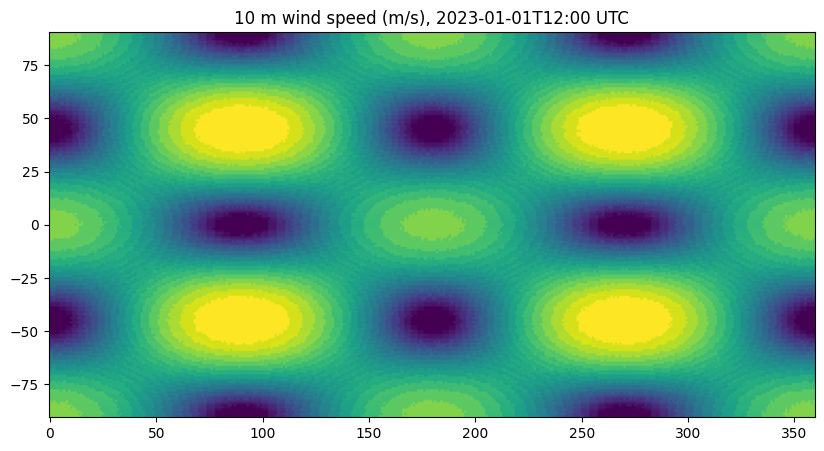

In [0]:
HOUR = "2023-01-01T12:00"

whole_grid = gbx_zarr_read(
    spark, STORE, variables=["wind_speed"], sel={"time": HOUR},
    output="tiles", tile_size=(360, 181), virtual_tiles=False,
).first()["tile"]
_ = plot_raster(whole_grid, cmap="viridis", fig_w=10, fig_h=5,
                title=f"10 m wind speed (m/s), {HOUR} UTC")

`rst_clip` clips the same hour to a polygon around Australia, written in the cube's 0 to 359
longitudes too. These tiles are **virtual** (the default): they hold no pixels until a function
opens them, and then read only the chunks their window touches. `rst_clip` returns a tile that
holds its pixels; it keeps a window of 41 x 28 cells. `rst_avg` and `rst_max` on the clipped
tile give the values the map has no scale for: the wind speed inside the polygon averages
3.23 m/s at that hour and peaks at 4.32 m/s.

In [0]:
AUSTRALIA = (
    "POLYGON((113 -22, 122 -17, 130 -12, 137 -12, 142 -10.5, 146 -18, 153 -25, 153.5 -29, "
    "150 -37.5, 141 -38.5, 135 -35, 129 -31.5, 115 -34.5, 113 -22))"
)

tiles = gbx_zarr_read(
    spark, STORE, variables=["wind_speed"], sel={"time": HOUR},
    output="tiles", tile_size=(360, 181),
)
clipped = tiles.select(
    rx.rst_clip("tile", F.lit(AUSTRALIA), F.lit(True)).alias("tile")
).select(
    "tile",
    rx.rst_width("tile").alias("width"),
    rx.rst_height("tile").alias("height"),
    F.round(rx.rst_avg("tile").getItem(0), 2).alias("mean_m_s"),
    F.round(rx.rst_max("tile").getItem(0), 2).alias("max_m_s"),
)
clipped.drop("tile").show()

+-----+------+--------+-------+
|width|height|mean_m_s|max_m_s|
+-----+------+--------+-------+
|   41|    28|    3.23|   4.32|
+-----+------+--------+-------+



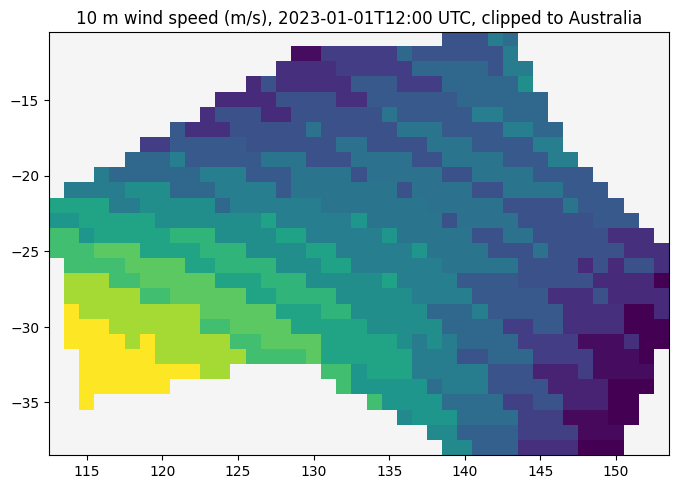

In [0]:
_ = plot_raster(
    clipped.first()["tile"],
    cmap="viridis",
    fig_w=8,
    fig_h=6,
    title=f"10 m wind speed (m/s), {HOUR} UTC, clipped to Australia",
)

## 7. Tag the version used for training

A store keeps its old versions readable for its `retain` period (7 days by default). A model's
training data needs longer than that, so **tag** the version: a tag copies that version's manifest
rows under a name, and neither GeoBrix's vacuum nor Delta's own `VACUUM` removes what a tag points
at. Read it back with `version_as_of="tag:<name>"`.

The features table holds the four variables and the wind speed derived from them. Version 2 holds
all five as variables of the store, so it is the version to tag. Sampling the sites from the tag
gives back all 4,800 rows of the features table, with no row different.

The tag is itself a commit. In this run it is version 4: version 3 was an automatic compaction of
the manifest table by Delta (an `OPTIMIZE`), which is not a GeoBrix commit, so the history does not
list it.

In [0]:
gbx_zarr_tag(spark, STORE, "training", version_as_of=version_wind)

columns = ["site", "time", "t2m", "u10", "v10", "msl", "wind_speed"]
reproduced = gbx_zarr_sample(
    spark, sites, STORE, variables=columns[2:], version_as_of="tag:training"
).select(columns)
print("rows from the tag:", reproduced.count())
differing = reproduced.exceptAll(features.select(columns)).count()
print("rows that differ from the features table:", differing)
assert differing == 0, "the tagged version does not reproduce the features table"

gbx_zarr_history(spark, STORE).select("version", "mode", "variables").orderBy("version").show(
    truncate=False
)

rows from the tag: 4800
rows that differ from the features table: 0
+-------+--------+------------+
|version|mode    |variables   |
+-------+--------+------------+
|1      |register|NULL        |
|2      |update  |[wind_speed]|
|4      |tag     |NULL        |
+-------+--------+------------+



## The cube is unchanged

Everything this notebook wrote went to its overlay folder and its tables. The registered cube has
the same 19 files, with the same sizes and modification times, as before the registration. The
overlay holds 5 files, about 1.45 MB in all: the pack file of `wind_speed` and the folder's
ownership records (`_gbx_owner`, a small Delta table, and the `_gbx_store.json` marker).

In [0]:
cube_after = fingerprint(CUBE)
print("cube unchanged:", cube_after == cube_before, f"({len(cube_after)} files)")
assert cube_after == cube_before, "the registered cube was changed"
overlay = [p for p in pathlib.Path(f"{ROOT}/overlay").rglob("*") if p.is_file()]
print(len(overlay), "files in the overlay,", sum(p.stat().st_size for p in overlay), "bytes")

cube unchanged: True (19 files)
5 files in the overlay, 1448407 bytes


## Clean up

The tables and the overlay folder are kept, so the features table and the tagged store stay
available. Set `CLEAN_UP = True` to drop this run's two tables and delete its folder.

In [0]:
import shutil

CLEAN_UP = False

if CLEAN_UP:
    for table in (STORE, FEATURES):
        spark.sql(f"DROP TABLE IF EXISTS {table}")
    shutil.rmtree(ROOT, ignore_errors=True)
    left = [table for table in (STORE, FEATURES) if spark.catalog.tableExists(table)]
    left += [ROOT] if pathlib.Path(ROOT).exists() else []
    if left:
        print("not removed:", ", ".join(left))
    else:
        print("removed", STORE, FEATURES, ROOT)
else:
    print("kept", STORE, FEATURES, ROOT)

kept geospatial_docs.geobrix.era5_weather_3b6f091e geospatial_docs.geobrix.era5_site_features_3b6f091e /Volumes/geospatial_docs/geobrix/sample-data/_examples/zarr-weather/3b6f091e
